# Chaotic stirring 1: the blinking vortex

**37EFM Environmental Fluid Mechanics, TU/e**

Two point vortices, a distance $2a$ apart, are switched on alternately, each for half a period $T$ (Aref 1984; Chapter 7 of the lecture notes, section *Chaotic advection*). At every instant the flow is steady, axisymmetric and laminar, yet the trajectories can be chaotic. This notebook draws Poincaré sections, follows blobs of dye, and measures the stirring in three ways: the Lyapunov exponent, the finite-time Lyapunov exponent (FTLE) and the finite-size Lyapunov exponent (FSLE).

Lengths are in units of $a$, with the vortices at $x = \pm 1$, and time is in periods. The only parameter is

$$\mu = \frac{\Gamma T}{4\pi a^2},$$

the angle through which a parcel at distance $a$ from the active vortex turns while that vortex is on; at distance $r$ it turns through $\mu a^2/r^2$. Within each half period the rotation is uniform in time, so the motion is computed exactly, without numerical integration.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import efmstir
from efmstir import lyapunov as L
plt.rcParams['figure.dpi'] = 80

def vortices(ax):
    ax.scatter([-1, 1], [0, 0], marker='x', color='C3', s=60, zorder=5)

## The flow

One parcel over two periods, for $\mu = 0.8$. It turns about the left vortex during the first half of each period and about the right one during the second half; the dots mark the switches.

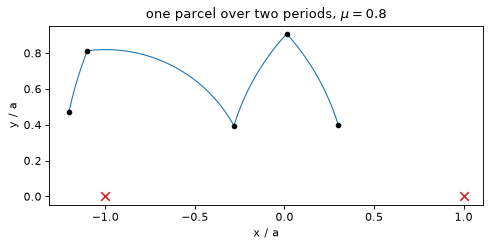

In [2]:
flow = efmstir.BlinkingVortex(0.8)
x, y, t, dt = np.array(0.3), np.array(0.4), 0.0, 0.01
track = [(float(x), float(y))]
for k in range(200):
    x, y, _ = flow.step(x, y, t, dt)
    t += dt
    track.append((float(x), float(y)))
track = np.array(track)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(track[:, 0], track[:, 1], lw=1)
ax.plot(track[::50, 0], track[::50, 1], 'ko', ms=4)
vortices(ax)
ax.set_aspect('equal'); ax.set_xlabel('x / a'); ax.set_ylabel('y / a')
ax.set_title(r'one parcel over two periods, $\mu = 0.8$');

## Poincaré sections

Recording the parcels once per period gives a Poincaré section, as in the figure of Chapter 7 for $\mu = 0.15$ and $0.8$. Here the parcels start on the line between the vortices, $|x| < 0.7$, and are followed for 1000 periods. Each parcel has its own colour, so a closed curve traced by one colour is regular motion, and a cloud of one colour is chaotic.

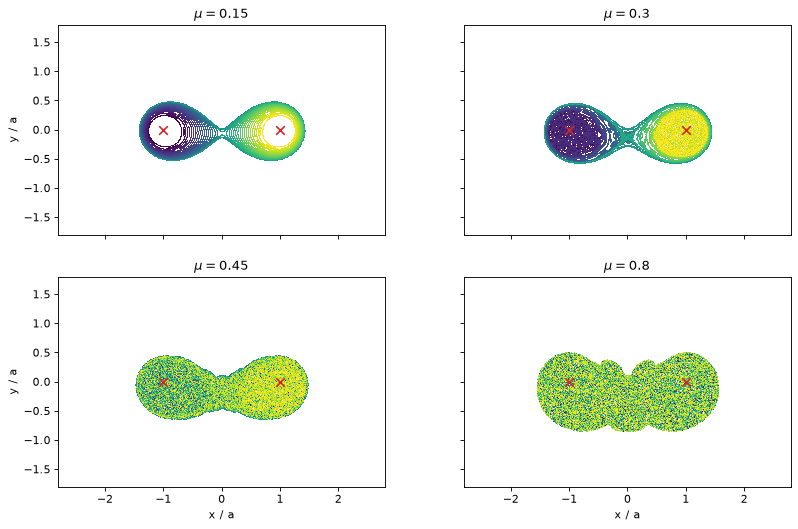

In [3]:
seeds = np.linspace(-0.7, 0.7, 41)

def poincare(mu, n=1000):
    flow = efmstir.BlinkingVortex(mu)
    x, y = seeds.copy(), np.zeros_like(seeds)
    pts = np.empty((n, 2, seeds.size))
    for k in range(n):
        x, y = flow.period_map(x, y)
        pts[k] = x, y
    return pts

colours = plt.cm.viridis(np.linspace(0, 1, seeds.size))
fig, axs = plt.subplots(2, 2, figsize=(12, 7.5), sharex=True, sharey=True)
for ax, mu in zip(axs.flat, [0.15, 0.3, 0.45, 0.8]):
    p = poincare(mu)
    for i in range(seeds.size):
        ax.plot(p[:, 0, i], p[:, 1, i], ',', color=colours[i])
    vortices(ax)
    ax.set_title(rf'$\mu = {mu}$'); ax.set_aspect('equal')
    ax.set_xlim(-2.8, 2.8); ax.set_ylim(-1.8, 1.8)
for ax in axs[-1]: ax.set_xlabel('x / a')
for ax in axs[:, 0]: ax.set_ylabel('y / a')

Even at $\mu = 0.8$, the section has a hole just above the middle, near $(0, 0.25)$: none of these parcels ever enters it. It is a regular island, a region of closed curves inside the chaotic sea, and the parcels started on the line $y = 0$ simply never reach it.

## Two blobs of dye

The outline of a blob is a material line: following it, and adding points wherever it stretches, shows the stirring directly. Two blobs are released, one at $(0, -0.3)$ and one at $(0, 0.22)$, the place of that island, for weak and for strong blinking.

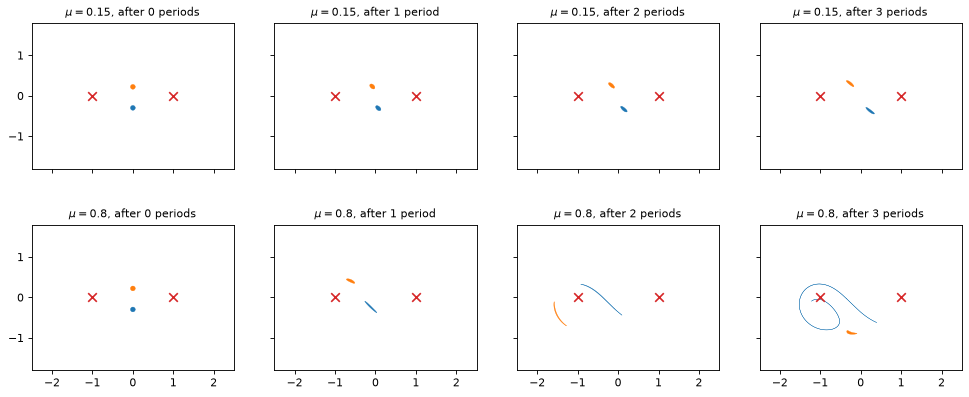

In [4]:
releases = {'released at (0, -0.3)': (0.0, -0.3), 'released at (0, 0.22)': (0.0, 0.22)}
blob = {}
for mu in (0.15, 0.8):
    flow = efmstir.BlinkingVortex(mu)
    for name, (xc, yc) in releases.items():
        blob[mu, name] = L.follow_outline(flow, *L.outline(xc, yc, 0.06), 0.0, 3, h=0.004)

fig, axs = plt.subplots(2, 4, figsize=(15, 6), sharex=True, sharey=True)
for row, mu in enumerate((0.15, 0.8)):
    for col, n in enumerate(range(4)):
        ax = axs[row, col]
        for colour, name in zip(('C0', 'C1'), releases):
            xo, yo = blob[mu, name][n]
            ax.fill(xo, yo, color=colour, lw=0)
            ax.plot(np.r_[xo, xo[0]], np.r_[yo, yo[0]], color=colour, lw=0.3)
        vortices(ax)
        ax.set_aspect('equal'); ax.set_xlim(-2.5, 2.5); ax.set_ylim(-1.8, 1.8)
        ax.set_title(rf'$\mu = {mu}$, after {n} period{"" if n == 1 else "s"}', fontsize=10)

For strong blinking, the blob released in the sea is drawn into a filament and wound around the left vortex. The other one is hardly deformed, although it moves a long way: the island at $(0, 0.22)$ is one of a chain of islands, and the flow carries it from one island of the chain to the next each period, without stretching it.

The area of a blob is conserved, so its outline can only grow by thinning the blob into filaments. The length of the outline is a direct measure of the stretching.

mu = 0.8, blob in the sea: the outline grows by a factor e^1.24 per period over periods 1 to 3


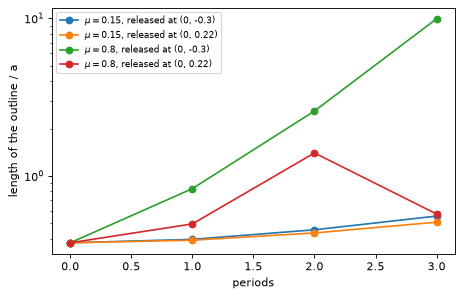

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for (mu, name), run in blob.items():
    ax.semilogy(range(len(run)), [L.length(*o) for o in run], 'o-', label=rf'$\mu = {mu}$, {name}')
ax.set_xlabel('periods'); ax.set_ylabel('length of the outline / a'); ax.legend(fontsize=8)
run = blob[0.8, 'released at (0, -0.3)']
rate = np.log(L.length(*run[3]) / L.length(*run[1])) / 2
print(f'mu = 0.8, blob in the sea: the outline grows by a factor e^{rate:.2f} per period over periods 1 to 3')

Followed for longer, the outline of the blob in the sea passes so close to a vortex that it is wound around it many times within a period, and the number of points needed to draw it explodes. Three periods are enough to make the point.

## The Lyapunov exponent

Two parcels a distance $\delta_0$ apart separate as $\delta \sim \delta_0 e^{\lambda t}$ when the motion is chaotic, with $\lambda$ the Lyapunov exponent (Chapter 7, section *Stretching, folding and the Lyapunov exponent*). `L.lyapunov` carries an infinitesimal separation along with each parcel and renormalises it after every period, the method of the exercise on the blinking vortex in Chapter 7. For $\mu = 0.3$, the running estimate is shown for the parcels with the largest and the smallest exponent, and the exponent after 2000 periods for all the parcels started on the line between the vortices.

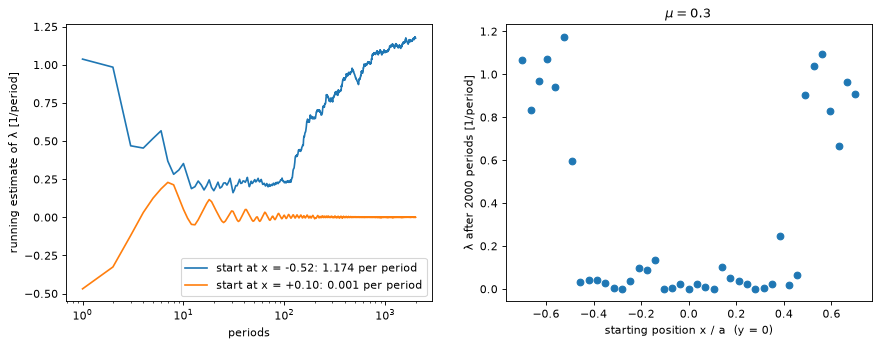

In [6]:
flow = efmstir.BlinkingVortex(0.3)
est = L.lyapunov(flow, seeds, np.zeros_like(seeds), 2000)     # shape (periods, parcels)
lam = est[-1]
n = np.arange(1, est.shape[0] + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for i in (np.argmax(lam), np.argmin(lam)):
    ax1.semilogx(n, est[:, i], label=f'start at x = {seeds[i]:+.2f}: {lam[i]:.3f} per period')
ax1.set_xlabel('periods'); ax1.set_ylabel('running estimate of λ [1/period]'); ax1.legend()
ax2.plot(seeds, lam, 'o')
ax2.set_xlabel('starting position x / a  (y = 0)'); ax2.set_ylabel('λ after 2000 periods [1/period]')
ax2.set_title(r'$\mu = 0.3$');

For $\mu = 0.3$, the parcels started near the vortices, $|x| > 0.5$, are chaotic, and those started near the middle are not. On a regular curve, the estimate keeps falling, roughly as $\ln n / n$: neighbouring parcels on nearby curves separate only linearly in time. In the chaotic band it settles at a positive value, close to the same for every parcel in the band, because each of them eventually visits all of it. It can take long to get there: the chaotic parcel above stays near 0.25 for about a hundred periods. It was trapped close to the edge of a regular region, where the motion is almost regular, before it escaped into the rest of the band.

How do the size of the chaotic region and the exponent within it change with $\mu$?

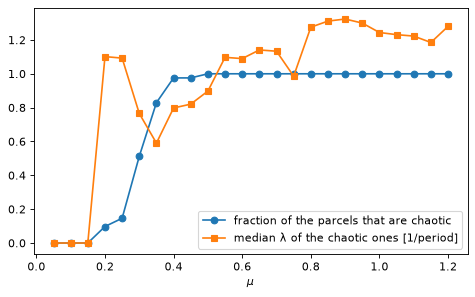

In [7]:
mus = np.round(np.arange(0.05, 1.21, 0.05), 2)
fraction, lam_sea = [], []
for mu in mus:
    lam = L.lyapunov(efmstir.BlinkingVortex(mu), seeds, np.zeros_like(seeds), 1000)[-1]
    chaotic = lam > 0.05
    fraction.append(chaotic.mean())
    lam_sea.append(np.median(lam[chaotic]) if chaotic.any() else 0.0)

fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.plot(mus, fraction, 'o-', label='fraction of the parcels that are chaotic')
ax1.plot(mus, lam_sea, 's-', label='median λ of the chaotic ones [1/period]')
ax1.set_xlabel(r'$\mu$'); ax1.legend();

## Finite-time Lyapunov exponents

The Lyapunov exponent is a single number for a whole chaotic region, and only reached after a long time. A patch of dye, an estuary or a tidal basin is watched for a finite time. The **finite-time Lyapunov exponent** asks how much a small blob around each starting point has been stretched after a time $\tau$:

$$\Lambda_\tau(\mathbf x_0) = \frac{1}{|\tau|}\ln \sigma_{\max},$$

with $\sigma_{\max}$ the largest stretching factor of the flow map, the largest singular value of its Jacobian $\partial \mathbf x(t_0 + \tau)/\partial \mathbf x_0$. It is a field over the starting points. For $\mu = 0.3$, over 1, 4 and 16 periods:

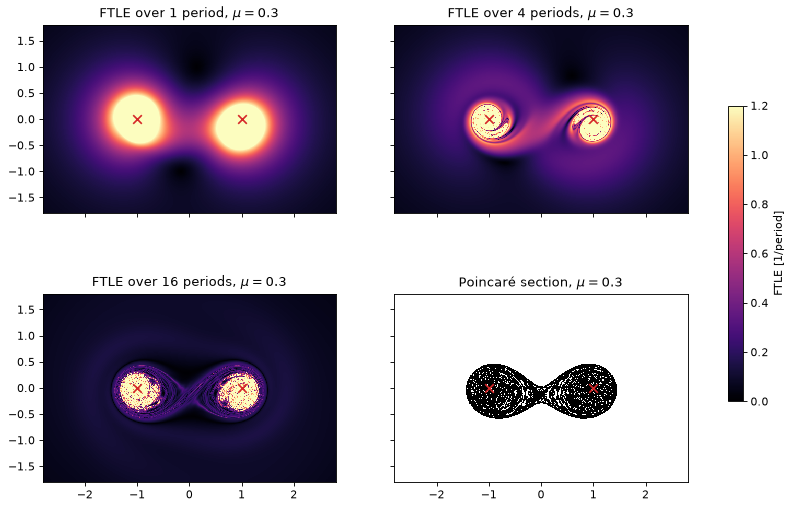

In [8]:
X, Y = np.meshgrid(np.linspace(-2.8, 2.8, 561), np.linspace(-1.8, 1.8, 361))
flow = efmstir.BlinkingVortex(0.3)
fig, axs = plt.subplots(2, 2, figsize=(13, 8), sharex=True, sharey=True)
for ax, tau in zip(axs.flat, [1, 4, 16]):
    f = L.ftle(flow, X, Y, 0.0, tau)
    im = ax.pcolormesh(X, Y, f, vmin=0, vmax=1.2, cmap='magma', shading='auto')
    ax.set_title(rf'FTLE over {tau} period{"s" if tau > 1 else ""}, $\mu = 0.3$')
p = poincare(0.3, n=500)
ax = axs[1, 1]
ax.plot(p[:, 0].ravel(), p[:, 1].ravel(), ',', color='k')
ax.set_title(r'Poincaré section, $\mu = 0.3$')
for ax in axs.flat:
    vortices(ax); ax.set_aspect('equal')
fig.colorbar(im, ax=axs, shrink=0.6, label='FTLE [1/period]');

After one period, the FTLE mostly shows where the flow shears strongly, around the vortices. As $\tau$ grows, the field away from the vortices fades towards zero: there, parcels separate only linearly, and $\ln(\text{linear growth})/\tau$ goes to zero. What stays bright is where stretching keeps up period after period: the chaotic band, threaded by sharp lines of high FTLE, and the close surroundings of the vortices, where the shear is so strong that even linear separation is fast. The sharp lines, or ridges, are the lines from which neighbouring parcels are pushed apart the most, the *Lagrangian coherent structures* (Shadden et al. 2005).

For strong blinking, the FTLE of parcels in the chaotic sea converges to the Lyapunov exponent as $\tau$ grows, and its spread narrows. The parcels below are those with a positive exponent after 300 periods, so that the island is left out.

93% of the parcels are in the chaotic sea, where the Lyapunov exponent is 1.27 per period


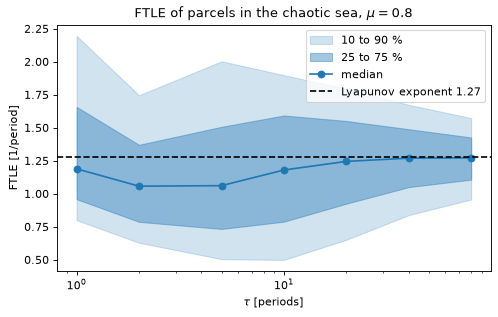

In [9]:
flow = efmstir.BlinkingVortex(0.8)
rng = np.random.default_rng(1)
xr, yr = rng.uniform(-0.7, 0.7, 4000), rng.uniform(-0.3, 0.3, 4000)
lam_r = L.lyapunov(flow, xr, yr, 300)[-1]
sea = lam_r > 0.5
lam_08 = np.median(lam_r[sea])
print(f'{sea.mean():.0%} of the parcels are in the chaotic sea, where the Lyapunov exponent is {lam_08:.2f} per period')

taus = [1, 2, 5, 10, 20, 40, 80]
pct = np.array([np.percentile(L.ftle(flow, xr[sea], yr[sea], 0.0, tau), [10, 25, 50, 75, 90]) for tau in taus])
fig, ax = plt.subplots(figsize=(7, 4))
ax.fill_between(taus, pct[:, 0], pct[:, 4], alpha=0.2, color='C0', label='10 to 90 %')
ax.fill_between(taus, pct[:, 1], pct[:, 3], alpha=0.4, color='C0', label='25 to 75 %')
ax.plot(taus, pct[:, 2], 'o-', color='C0', label='median')
ax.axhline(lam_08, color='k', ls='--', label=f'Lyapunov exponent {lam_08:.2f}')
ax.set_xscale('log'); ax.set_xlabel(r'$\tau$ [periods]'); ax.set_ylabel('FTLE [1/period]'); ax.legend()
ax.set_title(r'FTLE of parcels in the chaotic sea, $\mu = 0.8$');

### Where the dye goes: the backward FTLE

The forward FTLE marks the lines that *repel* parcels. Running the flow backward in time ($\tau < 0$) gives the lines that *attract* them, and a blob of dye is drawn out along those. Below, the blob released in the sea at $t = 0$ is drawn after 3 periods on top of the backward FTLE at $t = 3$, computed over the same 3 periods.

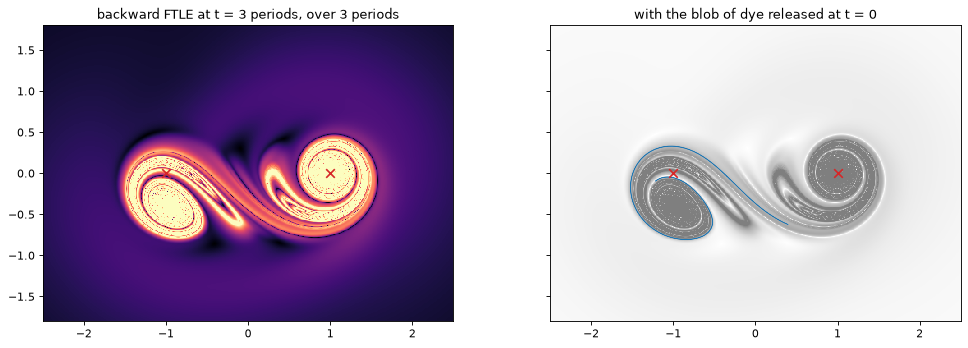

In [10]:
flow = efmstir.BlinkingVortex(0.8)
f_back = L.ftle(flow, X, Y, 3.0, -3.0)
xo, yo = blob[0.8, 'released at (0, -0.3)'][3]
fig, axs = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
axs[0].pcolormesh(X, Y, f_back, vmin=0, vmax=2.0, cmap='magma', shading='auto')
axs[0].set_title('backward FTLE at t = 3 periods, over 3 periods')
axs[1].pcolormesh(X, Y, f_back, vmin=0, vmax=2.0, cmap='Greys', shading='auto', alpha=0.5)
axs[1].plot(np.r_[xo, xo[0]], np.r_[yo, yo[0]], color='C0', lw=0.5)
axs[1].set_title('with the blob of dye released at t = 0')
for ax in axs:
    vortices(ax); ax.set_aspect('equal'); ax.set_xlim(-2.5, 2.5); ax.set_ylim(-1.8, 1.8)

## Finite-size Lyapunov exponents

The FTLE fixes the time and measures the stretching. The **finite-size Lyapunov exponent** does the opposite: it fixes the stretching and measures the time (Aurell et al. 1997; Artale et al. 1997). Two parcels are a distance $\delta$ apart; $\tau(\delta)$ is the time until they are $r\delta$ apart, and

$$\lambda(\delta) = \frac{\ln r}{\langle \tau(\delta) \rangle},$$

averaged over many pairs. For small $\delta$ it tends to the Lyapunov exponent. Once the separation is comparable to the size of the flow structures, here the distance between the vortices, it falls: the two parcels are no longer stretched apart by the same velocity gradient, and the region over which they can separate is finite. The FSLE is therefore the growth rate that matters for a patch of finite size. Here $r = 2$, and the separations are compared once per period, at the same phase of the flow, as in the Poincaré section.

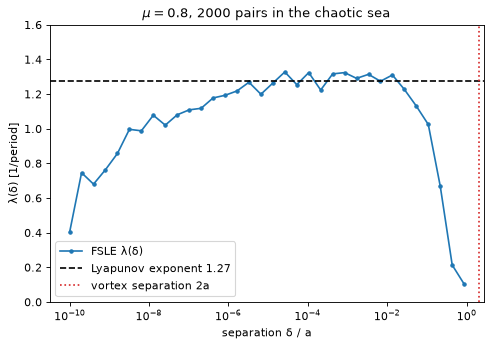

In [11]:
flow = efmstir.BlinkingVortex(0.8)
delta, fsle, npairs = L.fsle_curve(flow, xr[sea][:2000], yr[sea][:2000], delta0=1e-10, ratio=2.0,
                                   n_scales=36, t_max=300)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.semilogx(delta, fsle, 'o-', ms=3, label='FSLE λ(δ)')
ax.axhline(lam_08, color='k', ls='--', label=f'Lyapunov exponent {lam_08:.2f}')
ax.axvline(2, color='C3', ls=':', label='vortex separation 2a')
ax.set_ylim(0, 1.6)
ax.set_xlabel('separation δ / a'); ax.set_ylabel('λ(δ) [1/period]'); ax.legend(loc='lower left')
ax.set_title(r'$\mu = 0.8$, 2000 pairs in the chaotic sea');

At the smallest separations, the FSLE is below the plateau: the pairs start in random directions, and it takes about ten periods, a factor $10^4$ in separation, before their separations have lined up with the direction of strongest stretching and the pairs that started near the islands have left them.

## Questions

1. In the Poincaré section for $\mu = 0.3$, find a regular island next to the chaotic band. Release a small blob inside it and another in the band next to it (`L.outline` and `L.follow_outline`), and compare the growth of their outlines.
2. Over periods 1 to 3, the outline of the blob in the sea grows at nearly the rate of the Lyapunov exponent. Once the outline has been folded many times, should it grow faster, as fast, or slower than a single infinitesimal separation? Follow a blob released at the origin for five periods and check.
3. Why are the FTLE values high close to the vortices even for $\mu = 0.15$, where there is no chaos? What separates that stretching from chaotic stretching? Compare the FTLE over 4 and over 40 periods.
4. Why does the dye follow the ridges of the *backward* FTLE, and not those of the forward FTLE?
5. At which separation does the FSLE fall below the Lyapunov exponent? What does that mean for a patch of dye as large as the distance between the vortices?
6. Compute the FSLE again with `dt=0.05`, comparing the separations twenty times per period. The plateau drops well below the Lyapunov exponent. Why? (Follow two parcels that circle a vortex at slightly different distances from it, and plot the distance between them against time.)
7. The Lyapunov exponent is per period. In the tidal setting of the exercise in Chapter 7, $T = 12.4$ h. How long does it take, with the exponent for $\mu = 0.8$, to stretch a filament by a factor $10^3$?

### References

- Aref, H. (1984). Stirring by chaotic advection. *Journal of Fluid Mechanics* 143, 1–21.
- Artale, V., Boffetta, G., Celani, A., Cencini, M. and Vulpiani, A. (1997). Dispersion of passive tracers in closed basins: beyond the diffusion coefficient. *Physics of Fluids* 9, 3162–3171.
- Aurell, E., Boffetta, G., Crisanti, A., Paladin, G. and Vulpiani, A. (1997). Predictability in the large: an extension of the concept of Lyapunov exponent. *Journal of Physics A* 30, 1–26.
- Shadden, S. C., Lekien, F. and Marsden, J. E. (2005). Definition and properties of Lagrangian coherent structures from finite-time Lyapunov exponents in two-dimensional aperiodic flows. *Physica D* 212, 271–304.